In [1]:
import os
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.models import (
    resnet18, ResNet18_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    resnet50, ResNet50_Weights
)
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)


mps


In [3]:
zip_path = "/Users/pearl/Downloads/Copy of car-damage-assessment-kaggle-dataset.zip"
extract_path = "/Users/pearl/Downloads/Copy of car-damage-assessment-kaggle-dataset"

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("Dataset ready.")


Dataset ready.


In [4]:
labels = pd.read_csv(os.path.join(extract_path, "data.csv"))

labels = labels.drop(columns=["Unnamed: 0"], errors="ignore")
labels = labels.drop_duplicates().reset_index(drop=True)

print("Rows:", len(labels))
print("Unique images:", labels["image"].nunique())
labels.head()


Rows: 1512
Unique images: 1512


,image,classes
0,image/0.jpeg,unknown
1,image/1.jpeg,head_lamp
2,image/2.jpeg,door_scratch
3,image/3.jpeg,head_lamp
4,image/4.jpeg,unknown


### Analysing Image Data


In [5]:
def get_image_info(image_path):
    path = os.path.join(extract_path, image_path)

    try:
        with Image.open(path) as img:
            width, height = img.size

            return pd.Series({
                "filename": os.path.basename(path),
                "width": width,
                "height": height,
                "mode": img.mode,
                "aspect_ratio": width / height,
                "format": img.format
            })

    except Exception as e:
        print("Problem with:", path, e)

        return pd.Series({
            "filename": None,
            "width": None,
            "height": None,
            "mode": None,
            "aspect_ratio": None,
            "format": None
        })


labels[
    ["filename", "width", "height", "mode", "aspect_ratio", "format"]
] = labels["image"].apply(get_image_info)


In [6]:
print(labels.shape)
labels.head()


(1512, 8)


,image,classes,filename,width,height,mode,aspect_ratio,format
0,image/0.jpeg,unknown,0.jpeg,224,224,RGB,1.0,JPEG
1,image/1.jpeg,head_lamp,1.jpeg,224,224,RGB,1.0,JPEG
2,image/2.jpeg,door_scratch,2.jpeg,224,224,RGB,1.0,JPEG
3,image/3.jpeg,head_lamp,3.jpeg,224,224,RGB,1.0,JPEG
4,image/4.jpeg,unknown,4.jpeg,224,224,RGB,1.0,JPEG


In [9]:
round(labels["classes"].value_counts(normalize=True)*100,2)

classes
unknown           36.31
door_dent         12.70
door_scratch      10.19
glass_shatter      9.06
tail_lamp          8.99
head_lamp          8.80
bumper_dent        8.53
bumper_scratch     5.42
Name: proportion, dtype: float64

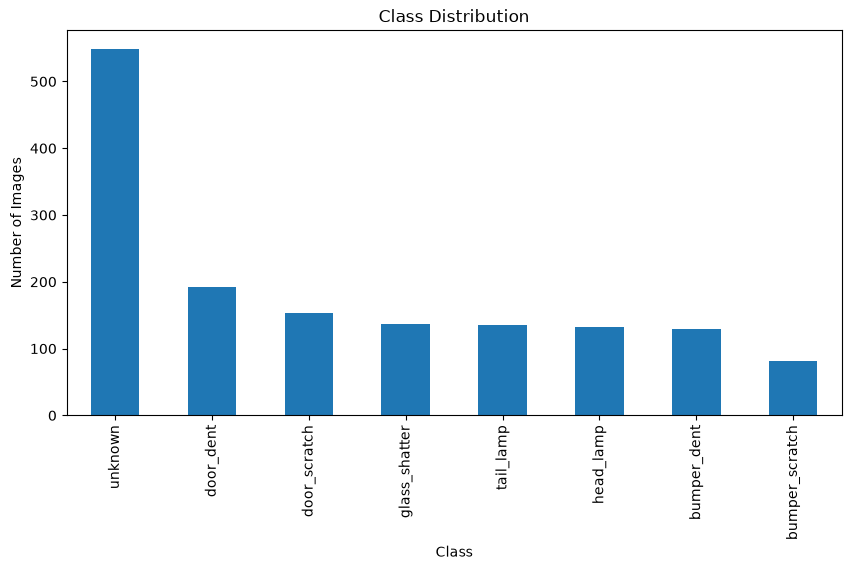

In [8]:
labels["classes"].value_counts().plot(
    kind="bar",
    figsize=(10, 5),
    title="Class Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()


In [10]:
print(labels["mode"].value_counts())
print(labels["format"].value_counts())

labels[["width", "height", "aspect_ratio"]].describe()


mode
RGB    1512
Name: count, dtype: int64
format
JPEG    1512
Name: count, dtype: int64


,width,height,aspect_ratio
count,1512.0,1512.0,1512.0
mean,224.0,224.0,1.0
std,0.0,0.0,0.0
min,224.0,224.0,1.0
25%,224.0,224.0,1.0
50%,224.0,224.0,1.0
75%,224.0,224.0,1.0
max,224.0,224.0,1.0


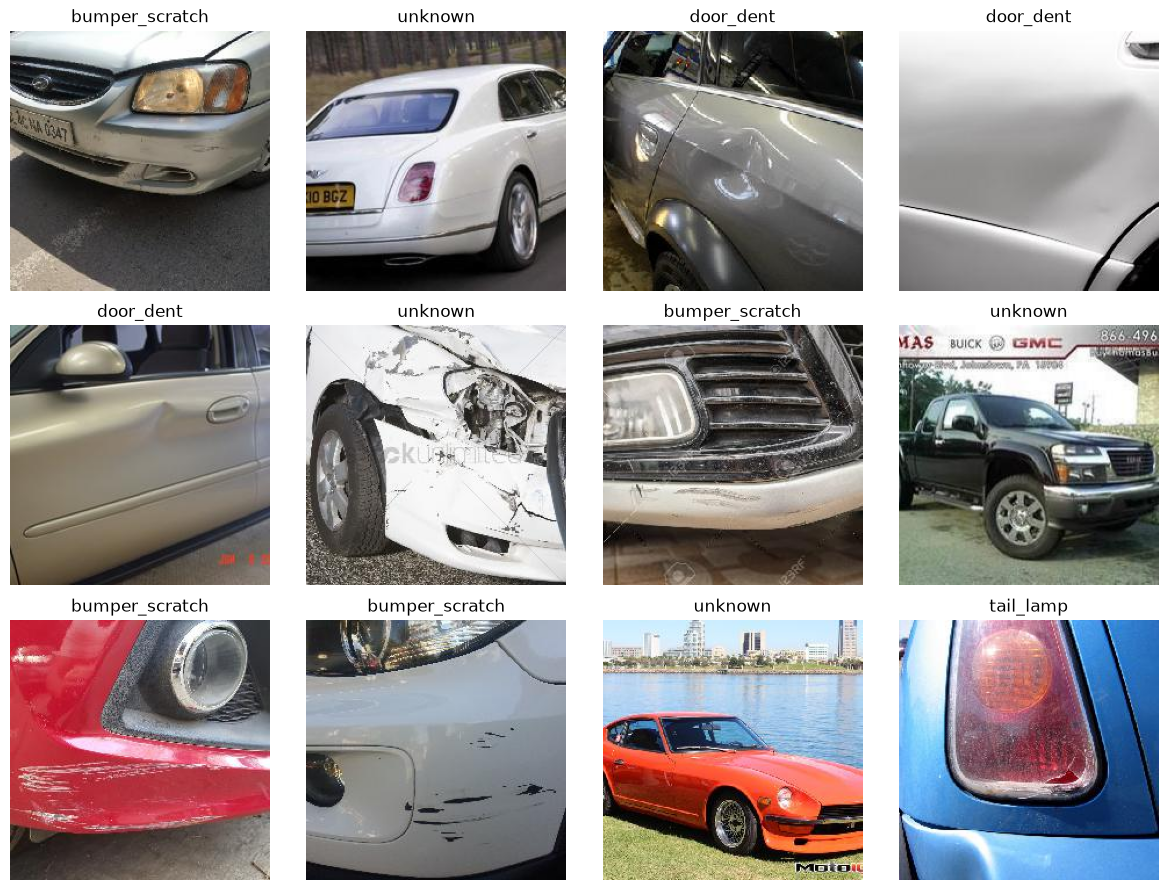

In [11]:
sample = labels.sample(12, random_state=SEED)

plt.figure(figsize=(12, 9))

for i, (_, row) in enumerate(sample.iterrows()):
    img = Image.open(os.path.join(extract_path, row["image"]))

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(row["classes"])
    plt.axis("off")

plt.tight_layout()
plt.show()


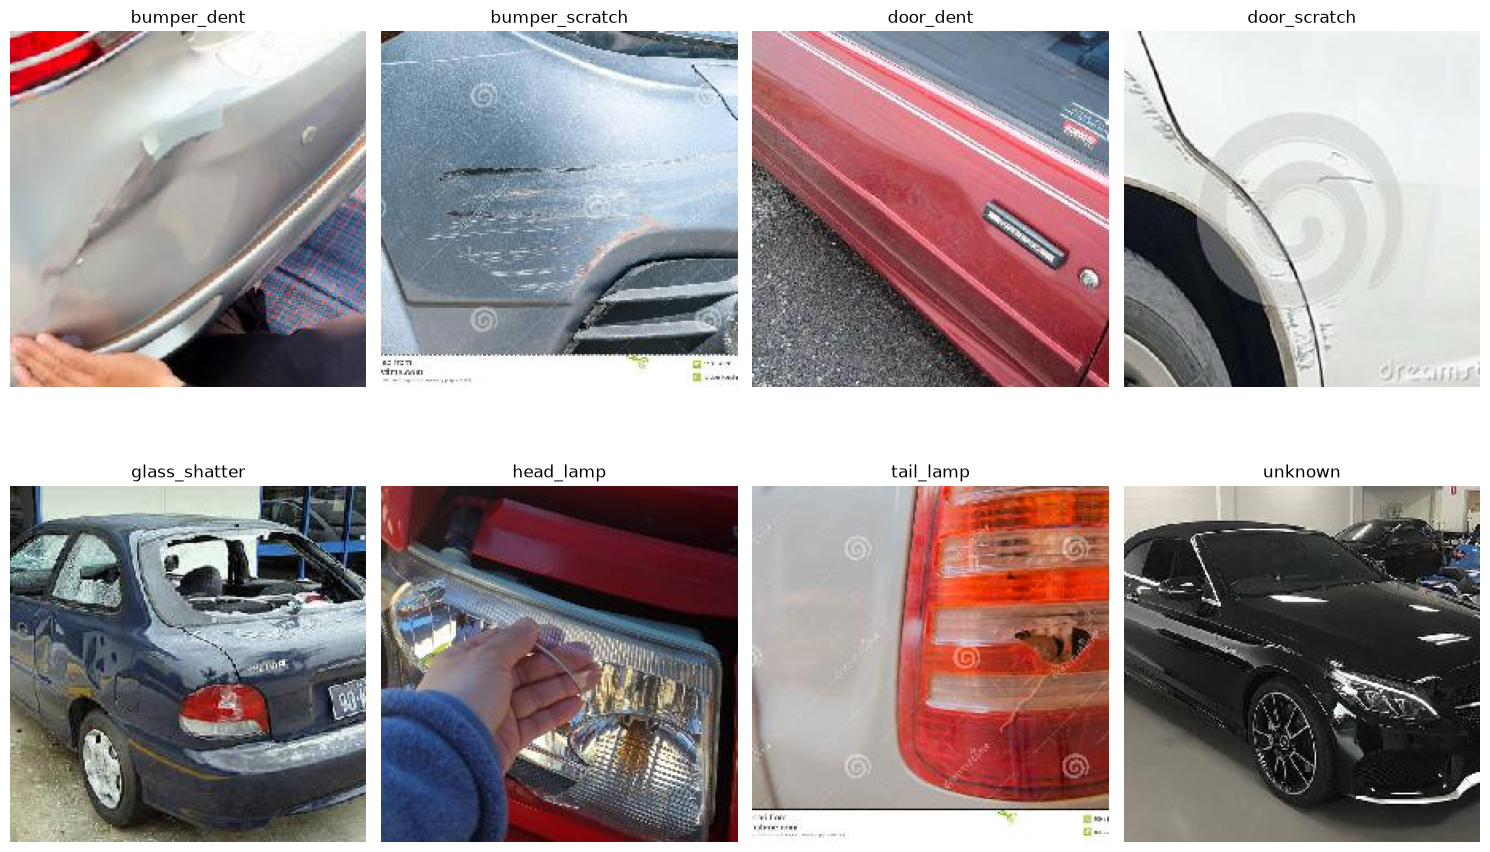

{'bumper_dent': 0,
 'bumper_scratch': 1,
 'door_dent': 2,
 'door_scratch': 3,
 'glass_shatter': 4,
 'head_lamp': 5,
 'tail_lamp': 6,
 'unknown': 7}

In [12]:
class_names = sorted(labels["classes"].unique())
class_to_idx = {cls: idx for idx, cls in enumerate(class_names)}

plt.figure(figsize=(15, 10))

for i, cls in enumerate(class_names):
    row = labels[labels["classes"] == cls].sample(1, random_state=SEED).iloc[0]
    img = Image.open(os.path.join(extract_path, row["image"]))

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.tight_layout()
plt.show()

class_to_idx


### Train / Validation / Test Split


In [13]:
train_df, temp_df = train_test_split(
    labels,
    test_size=0.30,
    stratify=labels["classes"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["classes"],
    random_state=SEED
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Train: 1058
Validation: 227
Test: 227


In [14]:
print(train_df["classes"].value_counts(normalize=True).sort_index())
print(val_df["classes"].value_counts(normalize=True).sort_index())
print(test_df["classes"].value_counts(normalize=True).sort_index())


classes
bumper_dent       0.085066
bumper_scratch    0.054820
door_dent         0.126654
door_scratch      0.102079
glass_shatter     0.090737
head_lamp         0.087902
tail_lamp         0.089792
unknown           0.362949
Name: proportion, dtype: float64
classes
bumper_dent       0.083700
bumper_scratch    0.052863
door_dent         0.127753
door_scratch      0.101322
glass_shatter     0.092511
head_lamp         0.088106
tail_lamp         0.088106
unknown           0.365639
Name: proportion, dtype: float64
classes
bumper_dent       0.088106
bumper_scratch    0.052863
door_dent         0.127753
door_scratch      0.101322
glass_shatter     0.088106
head_lamp         0.088106
tail_lamp         0.092511
unknown           0.361233
Name: proportion, dtype: float64


### Scratch CNN Pre-processing


In [15]:
temp_transform = transforms.ToTensor()

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
num_pixels = 0

for _, row in train_df.iterrows():
    with Image.open(os.path.join(extract_path, row["image"])) as img:
        img = temp_transform(img.convert("RGB"))

    channel_sum += img.sum(dim=(1, 2))
    channel_sum_sq += (img ** 2).sum(dim=(1, 2))
    num_pixels += img.shape[1] * img.shape[2]

mean = channel_sum / num_pixels
std = (channel_sum_sq / num_pixels - mean ** 2).sqrt()

print("Mean:", mean)
print("Std:", std)


Mean: tensor([0.4660, 0.4385, 0.4454])
Std: tensor([0.2864, 0.2801, 0.2847])


In [16]:
scratch_train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

scratch_eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])


In [17]:
class CarDamageDataset(Dataset):

    def __init__(self, dataframe, root_dir, class_to_idx, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image_path = os.path.join(self.root_dir, row["image"])

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        label = self.class_to_idx[row["classes"]]

        if self.transform:
            image = self.transform(image)

        return image, label


In [18]:
def create_loaders(train_transform, eval_transform, batch_size=32):
    train_dataset = CarDamageDataset(
        train_df, extract_path, class_to_idx, train_transform
    )

    val_dataset = CarDamageDataset(
        val_df, extract_path, class_to_idx, eval_transform
    )

    test_dataset = CarDamageDataset(
        test_df, extract_path, class_to_idx, eval_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader, test_loader


In [19]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    checkpoint_path,
    scheduler=None
):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")

    for epoch in range(epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, targets in train_loader:
            images = images.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, targets)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            correct += (outputs.argmax(dim=1) == targets).sum().item()
            total += targets.size(0)

        train_loss = running_loss / len(train_loader)
        train_acc = correct / total

        model.eval()

        running_val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, targets in val_loader:
                images = images.to(device)
                targets = targets.to(device)

                outputs = model(images)
                loss = criterion(outputs, targets)

                running_val_loss += loss.item()
                correct += (outputs.argmax(dim=1) == targets).sum().item()
                total += targets.size(0)

        val_loss = running_val_loss / len(val_loader)
        val_acc = correct / total

        if scheduler:
            scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), checkpoint_path)

        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device)
    )

    return history


In [20]:
def evaluate_model(model, test_loader):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, targets in test_loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(targets.numpy())

    accuracy = np.mean(
        np.array(all_predictions) == np.array(all_labels)
    )

    print(f"Test Accuracy: {accuracy:.4f}")

    print(
        classification_report(
            all_labels,
            all_predictions,
            labels=list(range(len(class_names))),
            target_names=class_names,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names)))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(10, 8))
    disp.plot(ax=ax, xticks_rotation=45)
    plt.show()

    return accuracy


In [21]:
def plot_history(history):
    plt.figure(figsize=(8, 5))
    plt.plot(history["train_acc"], label="Train Accuracy")
    plt.plot(history["val_acc"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()


### Scratch CNN V1


In [22]:
scratch_train_loader, scratch_val_loader, scratch_test_loader = create_loaders(
    scratch_train_transform,
    scratch_eval_transform
)

In [26]:
class CarDamageCNN(nn.Module):

    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(

            # 224 x 224
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 112 x 112
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 56 x 56
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 28 x 28
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(256 * 14 * 14, 512),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [27]:
class_counts = (
    train_df["classes"]
    .value_counts()
    .reindex(class_names)
)

class_weights = len(train_df) / (
    len(class_names) * class_counts
)

class_weights = torch.tensor(
    class_weights.values,
    dtype=torch.float32,
    device=device
)


In [28]:
scratch_model = CarDamageCNN(
    num_classes=len(class_names)
).to(device)

scratch_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

scratch_optimizer = torch.optim.Adam(
    scratch_model.parameters(),
    lr=0.001
)

scratch_history = train_model(
    scratch_model,
    scratch_train_loader,
    scratch_val_loader,
    scratch_criterion,
    scratch_optimizer,
    epochs=20,
    checkpoint_path="best_scratch_cnn_v1.pt"
)


Epoch [1/20] | Train Loss: 13.9193 | Train Acc: 0.1588 | Val Loss: 2.4950 | Val Acc: 0.2467
Epoch [2/20] | Train Loss: 2.4831 | Train Acc: 0.1843 | Val Loss: 2.0185 | Val Acc: 0.1850
Epoch [3/20] | Train Loss: 2.0076 | Train Acc: 0.2117 | Val Loss: 1.9328 | Val Acc: 0.2335
Epoch [4/20] | Train Loss: 2.0244 | Train Acc: 0.2136 | Val Loss: 1.8591 | Val Acc: 0.2291
Epoch [5/20] | Train Loss: 1.9795 | Train Acc: 0.1692 | Val Loss: 1.8163 | Val Acc: 0.2115
Epoch [6/20] | Train Loss: 1.9531 | Train Acc: 0.1909 | Val Loss: 1.8402 | Val Acc: 0.1982
Epoch [7/20] | Train Loss: 1.9479 | Train Acc: 0.1871 | Val Loss: 1.8394 | Val Acc: 0.2159
Epoch [8/20] | Train Loss: 1.8714 | Train Acc: 0.1900 | Val Loss: 1.6970 | Val Acc: 0.2026
Epoch [9/20] | Train Loss: 1.9190 | Train Acc: 0.1947 | Val Loss: 1.7548 | Val Acc: 0.2247
Epoch [10/20] | Train Loss: 1.8719 | Train Acc: 0.2013 | Val Loss: 1.6056 | Val Acc: 0.2467
Epoch [11/20] | Train Loss: 1.7955 | Train Acc: 0.2183 | Val Loss: 1.5756 | Val Acc: 0.2

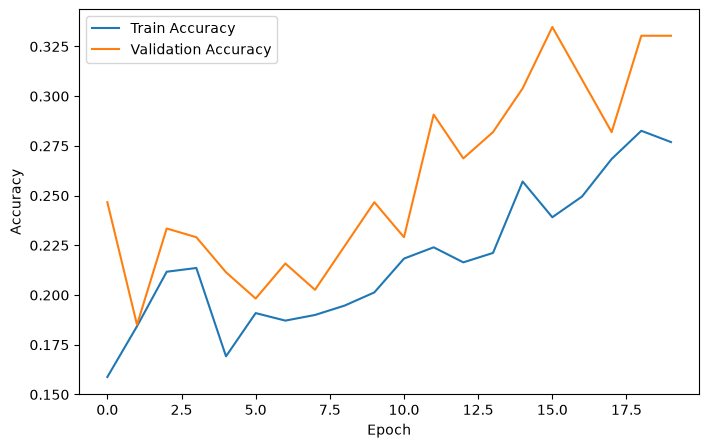

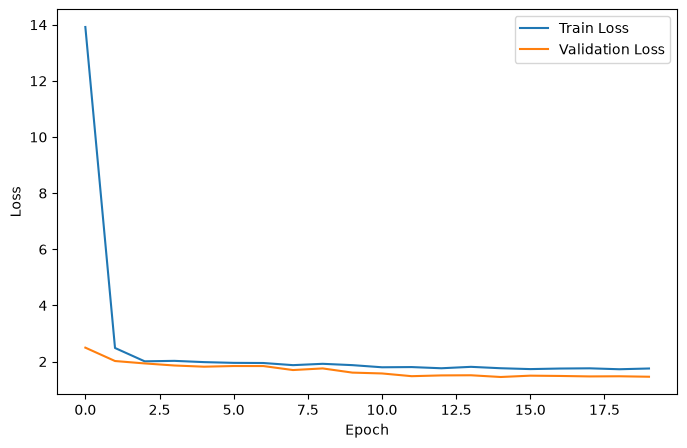

Test Accuracy: 0.3040
                precision    recall  f1-score   support

   bumper_dent       0.21      0.15      0.18        20
bumper_scratch       0.00      0.00      0.00        12
     door_dent       0.32      0.62      0.42        29
  door_scratch       0.00      0.00      0.00        23
 glass_shatter       0.22      0.80      0.34        20
     head_lamp       0.62      0.25      0.36        20
     tail_lamp       0.33      0.76      0.46        21
       unknown       0.55      0.13      0.22        82

      accuracy                           0.30       227
     macro avg       0.28      0.34      0.25       227
  weighted avg       0.36      0.30      0.25       227



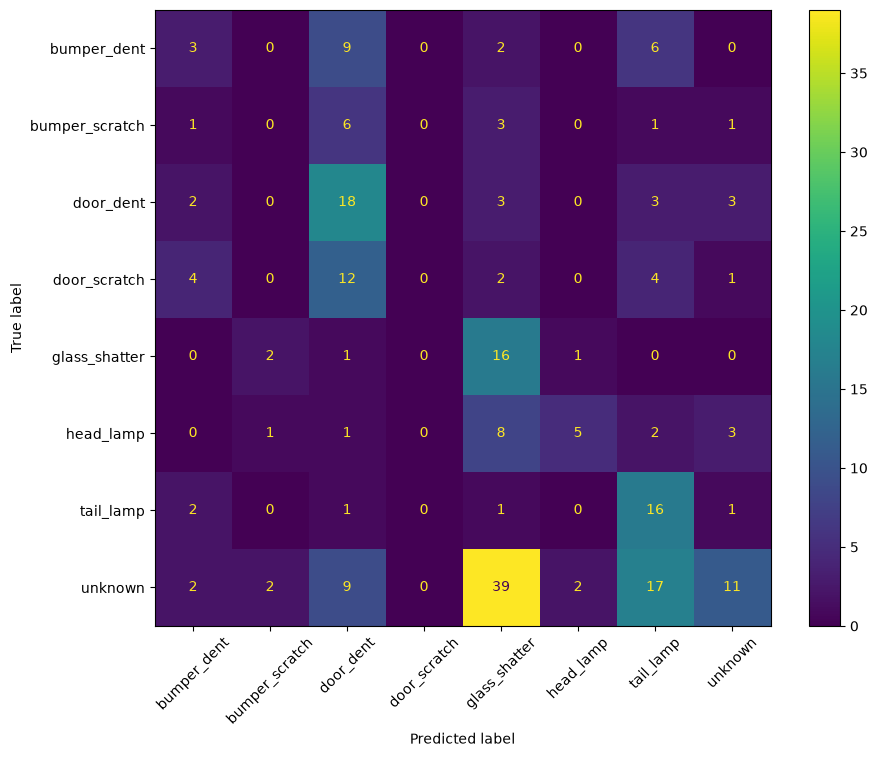

In [29]:
plot_history(scratch_history)
scratch_accuracy = evaluate_model(
    scratch_model,
    scratch_test_loader
)

### Pre-trained Model Pre-processing


In [30]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

pretrained_train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

pretrained_eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

train_loader, val_loader, test_loader = create_loaders(
    pretrained_train_transform,
    pretrained_eval_transform
)


### ResNet18


In [31]:
resnet18_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

resnet18_model.fc = nn.Linear(
    resnet18_model.fc.in_features,
    len(class_names)
)

resnet18_model = resnet18_model.to(device)

for param in resnet18_model.parameters():
    param.requires_grad = False

for param in resnet18_model.fc.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    resnet18_model.fc.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

resnet18_head_history = train_model(
    resnet18_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=8,
    checkpoint_path="best_resnet18_head.pt"
)


Epoch [1/8] | Train Loss: 1.7296 | Train Acc: 0.3960 | Val Loss: 1.4177 | Val Acc: 0.4846
Epoch [2/8] | Train Loss: 1.3582 | Train Acc: 0.5302 | Val Loss: 1.1308 | Val Acc: 0.6211
Epoch [3/8] | Train Loss: 1.1890 | Train Acc: 0.5898 | Val Loss: 0.9879 | Val Acc: 0.6960
Epoch [4/8] | Train Loss: 1.0740 | Train Acc: 0.6456 | Val Loss: 0.9662 | Val Acc: 0.6520
Epoch [5/8] | Train Loss: 1.0052 | Train Acc: 0.6767 | Val Loss: 0.9373 | Val Acc: 0.6652
Epoch [6/8] | Train Loss: 0.9631 | Train Acc: 0.6881 | Val Loss: 0.8254 | Val Acc: 0.7181
Epoch [7/8] | Train Loss: 0.8912 | Train Acc: 0.7212 | Val Loss: 0.7978 | Val Acc: 0.7313
Epoch [8/8] | Train Loss: 0.8757 | Train Acc: 0.7287 | Val Loss: 0.7742 | Val Acc: 0.7269


In [32]:
for param in resnet18_model.layer4.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, resnet18_model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

resnet18_layer4_history = train_model(
    resnet18_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=15,
    checkpoint_path="best_resnet18_layer4.pt",
    scheduler=scheduler
)


Epoch [1/15] | Train Loss: 0.6821 | Train Acc: 0.7722 | Val Loss: 0.5288 | Val Acc: 0.8062
Epoch [2/15] | Train Loss: 0.3857 | Train Acc: 0.8828 | Val Loss: 0.5141 | Val Acc: 0.8326
Epoch [3/15] | Train Loss: 0.2644 | Train Acc: 0.9206 | Val Loss: 0.4906 | Val Acc: 0.8150
Epoch [4/15] | Train Loss: 0.1834 | Train Acc: 0.9490 | Val Loss: 0.4665 | Val Acc: 0.8502
Epoch [5/15] | Train Loss: 0.1572 | Train Acc: 0.9735 | Val Loss: 0.4570 | Val Acc: 0.8502
Epoch [6/15] | Train Loss: 0.1773 | Train Acc: 0.9754 | Val Loss: 0.4920 | Val Acc: 0.8502
Epoch [7/15] | Train Loss: 0.1489 | Train Acc: 0.9716 | Val Loss: 0.4647 | Val Acc: 0.8414
Epoch [8/15] | Train Loss: 0.0824 | Train Acc: 0.9858 | Val Loss: 0.4767 | Val Acc: 0.8546
Epoch [9/15] | Train Loss: 0.0976 | Train Acc: 0.9830 | Val Loss: 0.4552 | Val Acc: 0.8458
Epoch [10/15] | Train Loss: 0.0567 | Train Acc: 0.9953 | Val Loss: 0.4701 | Val Acc: 0.8502
Epoch [11/15] | Train Loss: 0.0765 | Train Acc: 0.9858 | Val Loss: 0.4688 | Val Acc: 0.85

In [33]:
for param in resnet18_model.layer3.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, resnet18_model.parameters()),
    lr=5e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

resnet18_history = train_model(
    resnet18_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=15,
    checkpoint_path="best_resnet18_layer3_layer4.pt",
    scheduler=scheduler
)


Epoch [1/15] | Train Loss: 0.1263 | Train Acc: 0.9820 | Val Loss: 0.4813 | Val Acc: 0.8546
Epoch [2/15] | Train Loss: 0.1750 | Train Acc: 0.9877 | Val Loss: 0.4249 | Val Acc: 0.8678
Epoch [3/15] | Train Loss: 0.0754 | Train Acc: 0.9924 | Val Loss: 0.4362 | Val Acc: 0.8722
Epoch [4/15] | Train Loss: 0.0595 | Train Acc: 0.9943 | Val Loss: 0.4526 | Val Acc: 0.8722
Epoch [5/15] | Train Loss: 0.0447 | Train Acc: 0.9962 | Val Loss: 0.4467 | Val Acc: 0.8590
Epoch [6/15] | Train Loss: 0.0440 | Train Acc: 0.9934 | Val Loss: 0.4573 | Val Acc: 0.8722
Epoch [7/15] | Train Loss: 0.0272 | Train Acc: 1.0000 | Val Loss: 0.5040 | Val Acc: 0.8634
Epoch [8/15] | Train Loss: 0.0340 | Train Acc: 0.9962 | Val Loss: 0.4609 | Val Acc: 0.8678
Epoch [9/15] | Train Loss: 0.0598 | Train Acc: 0.9962 | Val Loss: 0.4923 | Val Acc: 0.8722
Epoch [10/15] | Train Loss: 0.0364 | Train Acc: 0.9953 | Val Loss: 0.4627 | Val Acc: 0.8722
Epoch [11/15] | Train Loss: 0.0325 | Train Acc: 0.9991 | Val Loss: 0.4663 | Val Acc: 0.87

Test Accuracy: 0.8722
                precision    recall  f1-score   support

   bumper_dent       1.00      0.75      0.86        20
bumper_scratch       0.75      0.75      0.75        12
     door_dent       0.89      0.83      0.86        29
  door_scratch       0.79      0.83      0.81        23
 glass_shatter       1.00      0.85      0.92        20
     head_lamp       0.88      0.70      0.78        20
     tail_lamp       0.90      0.90      0.90        21
       unknown       0.85      0.99      0.92        82

      accuracy                           0.87       227
     macro avg       0.88      0.82      0.85       227
  weighted avg       0.88      0.87      0.87       227



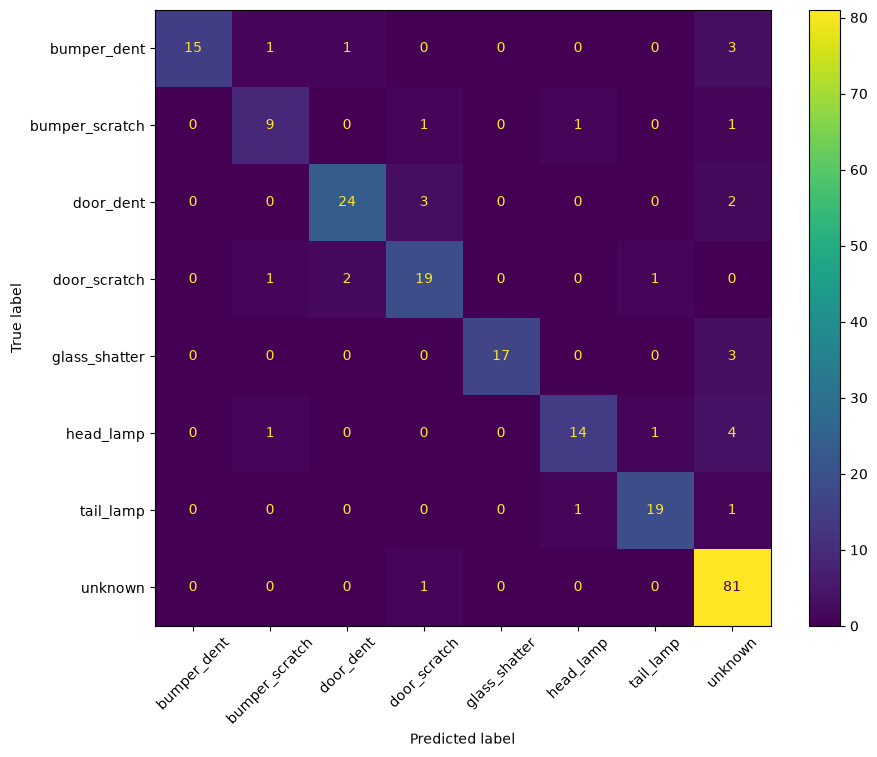

In [34]:
resnet18_accuracy = evaluate_model(
    resnet18_model,
    test_loader
)


## Test Accuracy - 87.22%

### EfficientNet-B0


In [35]:
efficientnet_model = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

efficientnet_model.classifier[1] = nn.Linear(
    efficientnet_model.classifier[1].in_features,
    len(class_names)
)

efficientnet_model = efficientnet_model.to(device)

for param in efficientnet_model.features.parameters():
    param.requires_grad = False

for param in efficientnet_model.classifier.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    efficientnet_model.classifier.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

efficientnet_head_history = train_model(
    efficientnet_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=8,
    checkpoint_path="best_efficientnet_b0_head.pt"
)


Epoch [1/8] | Train Loss: 1.6456 | Train Acc: 0.4263 | Val Loss: 1.3482 | Val Acc: 0.5463
Epoch [2/8] | Train Loss: 1.2587 | Train Acc: 0.6049 | Val Loss: 1.1421 | Val Acc: 0.6564
Epoch [3/8] | Train Loss: 1.0681 | Train Acc: 0.6796 | Val Loss: 1.0479 | Val Acc: 0.6652
Epoch [4/8] | Train Loss: 0.9557 | Train Acc: 0.7127 | Val Loss: 0.9509 | Val Acc: 0.6696
Epoch [5/8] | Train Loss: 0.8839 | Train Acc: 0.7401 | Val Loss: 0.9200 | Val Acc: 0.6476
Epoch [6/8] | Train Loss: 0.8302 | Train Acc: 0.7609 | Val Loss: 0.8745 | Val Acc: 0.6960
Epoch [7/8] | Train Loss: 0.7688 | Train Acc: 0.7665 | Val Loss: 0.8695 | Val Acc: 0.6564
Epoch [8/8] | Train Loss: 0.7179 | Train Acc: 0.7911 | Val Loss: 0.8090 | Val Acc: 0.6872


In [36]:
for param in efficientnet_model.features[-3:].parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, efficientnet_model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

efficientnet_history = train_model(
    efficientnet_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=15,
    checkpoint_path="best_efficientnet_b0_finetuned.pt",
    scheduler=scheduler
)


Epoch [1/15] | Train Loss: 0.6479 | Train Acc: 0.8129 | Val Loss: 0.6719 | Val Acc: 0.7269
Epoch [2/15] | Train Loss: 0.4971 | Train Acc: 0.8592 | Val Loss: 0.5883 | Val Acc: 0.7489
Epoch [3/15] | Train Loss: 0.3899 | Train Acc: 0.8781 | Val Loss: 0.5468 | Val Acc: 0.7709
Epoch [4/15] | Train Loss: 0.3727 | Train Acc: 0.9036 | Val Loss: 0.5056 | Val Acc: 0.7885
Epoch [5/15] | Train Loss: 0.2874 | Train Acc: 0.9301 | Val Loss: 0.4584 | Val Acc: 0.8326
Epoch [6/15] | Train Loss: 0.2302 | Train Acc: 0.9499 | Val Loss: 0.4357 | Val Acc: 0.8546
Epoch [7/15] | Train Loss: 0.2006 | Train Acc: 0.9480 | Val Loss: 0.4472 | Val Acc: 0.8194
Epoch [8/15] | Train Loss: 0.2170 | Train Acc: 0.9527 | Val Loss: 0.4232 | Val Acc: 0.8150
Epoch [9/15] | Train Loss: 0.1467 | Train Acc: 0.9726 | Val Loss: 0.3930 | Val Acc: 0.8370
Epoch [10/15] | Train Loss: 0.1712 | Train Acc: 0.9698 | Val Loss: 0.4044 | Val Acc: 0.8678
Epoch [11/15] | Train Loss: 0.1205 | Train Acc: 0.9707 | Val Loss: 0.3711 | Val Acc: 0.85

Test Accuracy: 0.8282
                precision    recall  f1-score   support

   bumper_dent       0.94      0.85      0.89        20
bumper_scratch       0.69      0.75      0.72        12
     door_dent       0.77      0.69      0.73        29
  door_scratch       0.76      0.83      0.79        23
 glass_shatter       1.00      0.80      0.89        20
     head_lamp       0.76      0.65      0.70        20
     tail_lamp       0.82      0.86      0.84        21
       unknown       0.84      0.93      0.88        82

      accuracy                           0.83       227
     macro avg       0.82      0.79      0.81       227
  weighted avg       0.83      0.83      0.83       227



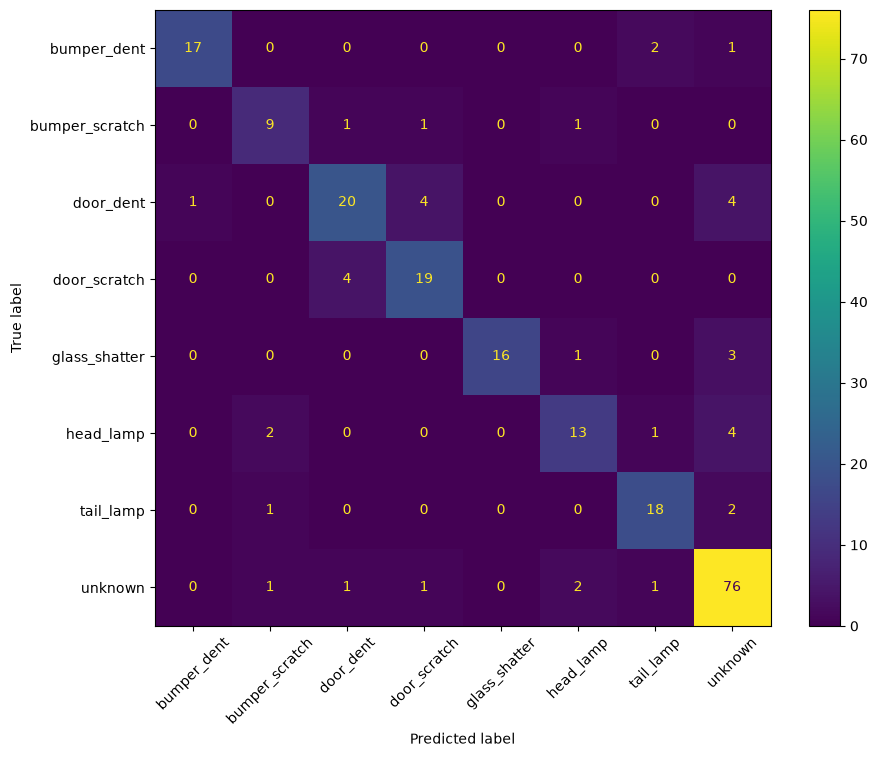

In [37]:
efficientnet_accuracy = evaluate_model(
    efficientnet_model,
    test_loader
)


## Test Accuracy went down to 82.82%

### ResNet50


In [38]:
resnet50_model = resnet50(
    weights=ResNet50_Weights.DEFAULT
)

resnet50_model.fc = nn.Linear(
    resnet50_model.fc.in_features,
    len(class_names)
)

resnet50_model = resnet50_model.to(device)

for param in resnet50_model.parameters():
    param.requires_grad = False

for param in resnet50_model.fc.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    resnet50_model.fc.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

resnet50_head_history = train_model(
    resnet50_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=8,
    checkpoint_path="best_resnet50_head.pt"
)


Epoch [1/8] | Train Loss: 1.6810 | Train Acc: 0.3941 | Val Loss: 1.2689 | Val Acc: 0.5286
Epoch [2/8] | Train Loss: 1.2605 | Train Acc: 0.6276 | Val Loss: 1.0097 | Val Acc: 0.6432
Epoch [3/8] | Train Loss: 1.0549 | Train Acc: 0.7051 | Val Loss: 0.8841 | Val Acc: 0.6916
Epoch [4/8] | Train Loss: 0.9098 | Train Acc: 0.7486 | Val Loss: 0.7871 | Val Acc: 0.7181
Epoch [5/8] | Train Loss: 0.8437 | Train Acc: 0.7750 | Val Loss: 0.7434 | Val Acc: 0.7401
Epoch [6/8] | Train Loss: 0.7897 | Train Acc: 0.7930 | Val Loss: 0.7112 | Val Acc: 0.7445
Epoch [7/8] | Train Loss: 0.7161 | Train Acc: 0.7940 | Val Loss: 0.6708 | Val Acc: 0.7577
Epoch [8/8] | Train Loss: 0.7287 | Train Acc: 0.8015 | Val Loss: 0.6825 | Val Acc: 0.7445


In [39]:
for param in resnet50_model.layer4.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, resnet50_model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

resnet50_history = train_model(
    resnet50_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=20,
    checkpoint_path="best_resnet50_layer4.pt",
    scheduler=scheduler
)


Epoch [1/20] | Train Loss: 0.5998 | Train Acc: 0.8053 | Val Loss: 0.5412 | Val Acc: 0.8194
Epoch [2/20] | Train Loss: 0.3604 | Train Acc: 0.8932 | Val Loss: 0.4864 | Val Acc: 0.8370
Epoch [3/20] | Train Loss: 0.2838 | Train Acc: 0.9282 | Val Loss: 0.4456 | Val Acc: 0.7974
Epoch [4/20] | Train Loss: 0.1815 | Train Acc: 0.9546 | Val Loss: 0.4271 | Val Acc: 0.8194
Epoch [5/20] | Train Loss: 0.1608 | Train Acc: 0.9631 | Val Loss: 0.4180 | Val Acc: 0.8370
Epoch [6/20] | Train Loss: 0.1120 | Train Acc: 0.9754 | Val Loss: 0.3962 | Val Acc: 0.8370
Epoch [7/20] | Train Loss: 0.1174 | Train Acc: 0.9887 | Val Loss: 0.4129 | Val Acc: 0.8414
Epoch [8/20] | Train Loss: 0.0757 | Train Acc: 0.9839 | Val Loss: 0.4293 | Val Acc: 0.8502
Epoch [9/20] | Train Loss: 0.0836 | Train Acc: 0.9877 | Val Loss: 0.4188 | Val Acc: 0.8502
Epoch [10/20] | Train Loss: 0.0742 | Train Acc: 0.9934 | Val Loss: 0.4110 | Val Acc: 0.8458
Epoch [11/20] | Train Loss: 0.0549 | Train Acc: 0.9934 | Val Loss: 0.4323 | Val Acc: 0.84

Test Accuracy: 0.8855
                precision    recall  f1-score   support

   bumper_dent       0.95      0.90      0.92        20
bumper_scratch       0.83      0.83      0.83        12
     door_dent       0.89      0.86      0.88        29
  door_scratch       0.86      0.83      0.84        23
 glass_shatter       0.86      0.90      0.88        20
     head_lamp       0.93      0.70      0.80        20
     tail_lamp       0.87      0.95      0.91        21
       unknown       0.89      0.94      0.91        82

      accuracy                           0.89       227
     macro avg       0.89      0.86      0.87       227
  weighted avg       0.89      0.89      0.88       227



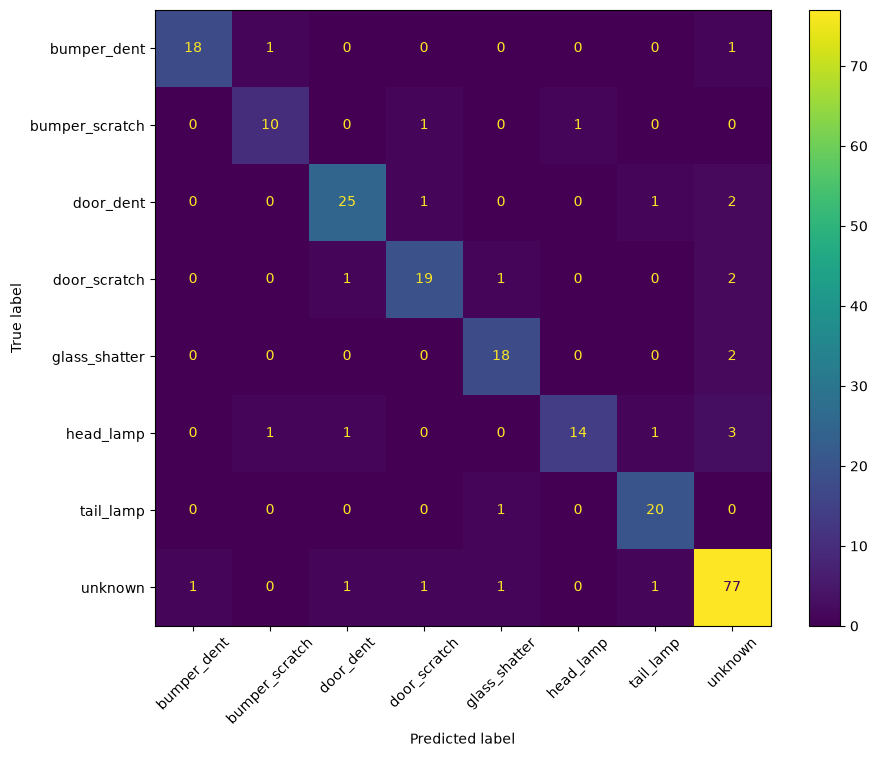

In [40]:
resnet50_accuracy = evaluate_model(
    resnet50_model,
    test_loader
)


In [44]:
torch.save(
    resnet50_model.state_dict(),
    "final_best_resnet50.pt"
)

## Test Accuracy - 88.55%

In [47]:
import json
import os

with open("class_to_idx.json", "w") as f:
    json.dump(class_to_idx, f, indent=4)

print("Saved to:", os.path.abspath("class_to_idx.json"))

Saved to: /Users/pearl/Downloads/class_to_idx.json


In [48]:
#Create a prediction function for a single new image
def predict_image(image_path, model, transform):
    model.eval()

    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)
        pred_idx = output.argmax(dim=1).item()

    return class_names[pred_idx]

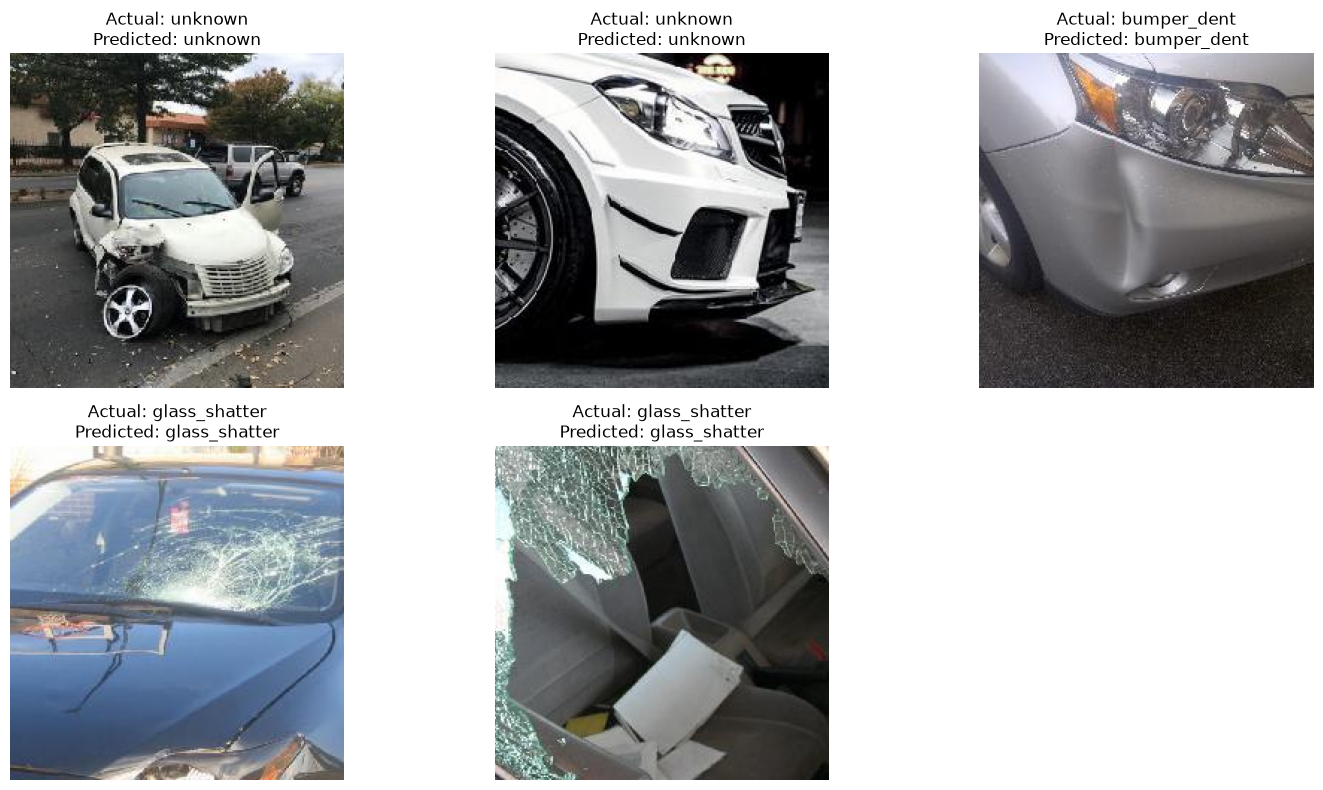

In [49]:
sample_images = test_df.sample(5, random_state=42)

plt.figure(figsize=(15, 8))

for i, (_, row) in enumerate(sample_images.iterrows()):

    image_path = os.path.join(
        extract_path,
        row["image"]
    )

    predicted_class = predict_image(
        image_path,
        resnet50_model,
        pretrained_eval_transform
    )

    actual_class = row["classes"]

    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

### Summary - Model Comparison


In [43]:
results = pd.DataFrame({
    "Model": [
        "Scratch CNN V1",
        "ResNet18",
        "EfficientNet-B0",
        "ResNet50"
    ],
    "Test Accuracy": [
        scratch_accuracy,
        resnet18_accuracy,
        efficientnet_accuracy,
        resnet50_accuracy
    ]
})

results.sort_values(
    "Test Accuracy",
    ascending=False
).reset_index(drop=True)


,Model,Test Accuracy
0,ResNet50,0.885463
1,ResNet18,0.872247
2,EfficientNet-B0,0.828194
3,Scratch CNN V1,0.303965
